# Fraud / Suspicious / Genuine - Logistic Regression vs XGBoost
Data sintetis v2 (`data_v2/`, 50.000 nasabah, 20,5 juta baris harian) mengikuti *Dynamic Customer Limit Proposal*.

* **Bagian A - deteksi level-hari** (`daydetect.parquet`): apakah hari ini fraud, dinilai real-time seperti *fraud gate* (§6.3).
  Hasilnya 3 pita: **genuine / suspicious / high-risk**.
* **Bagian B - skorecard 90 hari** (`snapshots.parquet`): risk target §5.3, dibandingkan dengan target dokumen (KS >= 35, Gini >= 0.45).

Catatan: negatif di Bagian A di-*down-sample* 3%. Kolom `weight` mengembalikan prevalensi asli, jadi semua metrik di bawah memakai `sample_weight`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import GroupShuffleSplit
from xgboost import XGBClassifier, DMatrix

DATA, NEG_KEEP = "data_v2", 0.03
CAT = ["gender", "region", "occupation", "segment"]
# fitur yang bergantung pada limit saat ini (model limit, bukan model fraud) dan kolom label/ID dikeluarkan
EXCLUDE = {"customer_id", "snap_date", "weight", "label_fraud_today", "label_fraud_90d", "_fraud_type", "_stealth",
           "near_limit_days_90", "declined_cnt_90", "baseline_tier"}

def ks(y, p, w): 
    fpr, tpr, _ = roc_curve(y, p, sample_weight=w); return float((tpr - fpr).max())

def fit_models(tr, feats, label, w_col=None, xgb_params=None):
    cat = [c for c in CAT if c in feats]; num = [c for c in feats if c not in cat]
    Xtr = tr[feats].copy()
    # validasi per-nasabah untuk early stopping XGBoost
    gi, vi = next(GroupShuffleSplit(1, test_size=0.15, random_state=0).split(Xtr, tr[label], tr["customer_id"]))
    params = dict(n_estimators=1500, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, tree_method="hist", enable_categorical=True, n_jobs=-1,
                  early_stopping_rounds=50, eval_metric="aucpr", random_state=42)
    params.update(xgb_params or {})
    xgb = XGBClassifier(**params).fit(Xtr.iloc[gi], tr[label].iloc[gi], eval_set=[(Xtr.iloc[vi], tr[label].iloc[vi])], verbose=False)
    # LR: transformasi kuantil (setara binning monoton ala WoE) + regularisasi L2
    lr = make_pipeline(SimpleImputer(strategy="median"), QuantileTransformer(n_quantiles=200, output_distribution="normal"),
                       LogisticRegression(max_iter=3000, C=0.3, class_weight="balanced"))
    lr.fit(tr[num], tr[label])
    return xgb, lr, num

def predict(xgb, lr, num, te, feats):
    return xgb.predict_proba(te[feats])[:, 1], lr.predict_proba(te[num])[:, 1]

def report(name, y, p, w):
    return dict(model=name, ROC_AUC=roc_auc_score(y, p, sample_weight=w), PR_AUC=average_precision_score(y, p, sample_weight=w),
                KS=ks(y, p, w), Gini=2 * roc_auc_score(y, p, sample_weight=w) - 1)

## Bagian A - deteksi fraud level-hari

In [2]:
day = pd.read_parquet(f"{DATA}/daydetect.parquet")
L = "label_fraud_today"
FEATS = [c for c in day.columns if c not in EXCLUDE]
train, test = day[day.snap_date < "2026-07-01"], day[day.snap_date >= "2026-07-01"]   # out-of-time
prev = np.average(day[L], weights=day.weight)
print(f"fitur: {len(FEATS)} | train {len(train):,} (fraud {train[L].sum():,}) | test OOT {len(test):,} (fraud {test[L].sum():,})")
print(f"prevalensi asli (terkoreksi bobot): {prev:.4%} per nasabah-hari")

fitur: 70 | train 359,008 (fraud 4,122) | test OOT 129,799 (fraud 1,066)
prevalensi asli (terkoreksi bobot): 0.0322% per nasabah-hari


In [3]:
xgb, lr, NUM = fit_models(train, FEATS, L)
p_x, p_l = predict(xgb, lr, NUM, test, FEATS)
y, w = test[L].values, test.weight.values
pd.DataFrame([report("Logistic Regression", y, p_l, w), report("XGBoost", y, p_x, w)]).round(3)

,model,ROC_AUC,PR_AUC,KS,Gini
0,Logistic Regression,0.973,0.118,0.831,0.945
1,XGBoost,0.999,0.685,0.963,0.997


### Pita risiko: genuine / suspicious / high-risk
Probabilitas dikoreksi prior (karena negatif di-down-sample), lalu ambang dipilih dari kurva presisi-recall berbobot:
**high-risk** = presisi >= 50% (blokir / hold), **suspicious** = presisi >= 5% (step-up auth / review manual); sisanya **genuine**.

In [4]:
def calibrate(p, k=NEG_KEEP): return p * k / (p * k + (1 - p))
def thresholds(y, p, w, prec_sus=0.05, prec_high=0.5):
    pr, rc, th = precision_recall_curve(y, p, sample_weight=w)
    first = lambda target: th[np.argmax(pr[:-1] >= target)] if (pr[:-1] >= target).any() else th[-1]
    t_sus, t_high = first(prec_sus), first(prec_high)
    return min(t_sus, t_high), t_high

def bands(y, p, w, t_sus, t_high):
    b = np.select([p >= t_high, p >= t_sus], ["high_risk", "suspicious"], "genuine")
    d = pd.DataFrame({"band": b, "w": w, "fraud": w * y}).groupby("band").sum()
    d["share_of_traffic"] = d.w / d.w.sum(); d["precision"] = d.fraud / d.w; d["share_of_fraud_caught"] = d.fraud / d.fraud.sum()
    return d.reindex(["genuine", "suspicious", "high_risk"]).fillna(0)[["share_of_traffic", "precision", "share_of_fraud_caught"]]

for name, p in (("XGBoost", p_x), ("Logistic Regression", p_l)):
    pc = calibrate(p); t_s, t_h = thresholds(y, pc, w)
    print(f"== {name}  (ambang suspicious={t_s:.4f}, high-risk={t_h:.4f})")
    display(bands(y, pc, w, t_s, t_h).style.format("{:.2%}"))

== XGBoost  (ambang suspicious=0.0012, high-risk=0.0340)


,share_of_traffic,precision,share_of_fraud_caught
band,,,
genuine,99.53%,0.00%,5.16%
suspicious,0.43%,0.86%,14.92%
high_risk,0.04%,50.55%,79.92%


== Logistic Regression  (ambang suspicious=0.8749, high-risk=0.9987)


,share_of_traffic,precision,share_of_fraud_caught
band,,,
genuine,99.81%,0.02%,61.82%
suspicious,0.19%,4.26%,31.89%
high_risk,0.00%,50.12%,6.29%


In [5]:
# Seberapa baik tiap tipe fraud tertangkap (recall pada ambang suspicious), termasuk varian stealth
pc = calibrate(p_x); t_s, t_h = thresholds(y, pc, w)
pos = test[test[L] == 1].assign(score=pc[test[L].values == 1])
pos["flag"] = np.where(pos.score >= t_h, "high_risk", np.where(pos.score >= t_s, "suspicious", "missed"))
pd.crosstab([pos._fraud_type, pos._stealth], pos.flag, normalize="index").round(3)

flag                  high_risk  missed  suspicious
_fraud_type _stealth                               
ato         0             0.871   0.065       0.065
            1             0.413   0.261       0.326
mule        0             0.877   0.048       0.074
            1             0.724   0.048       0.228
scam        0             0.910   0.000       0.090
            1             0.763   0.062       0.175

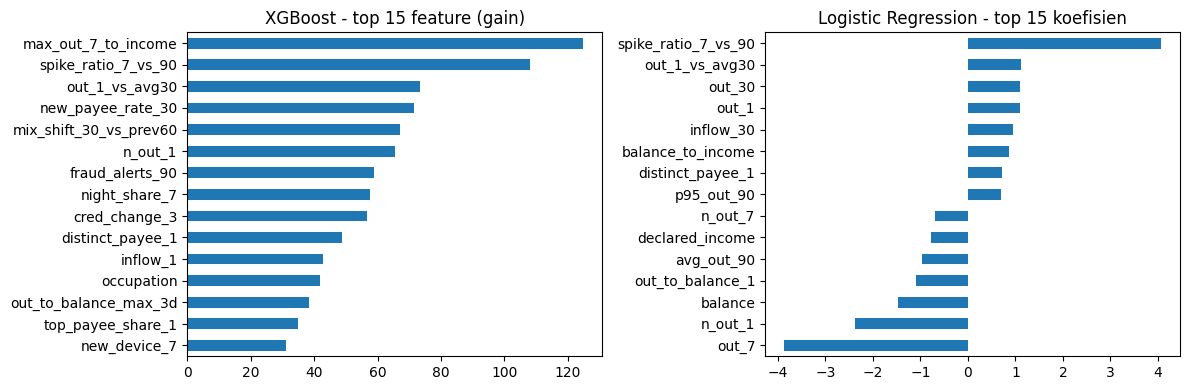

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).nlargest(15).sort_values()
imp.plot.barh(ax=ax[0], title="XGBoost - top 15 feature (gain)")
coef = pd.Series(lr[-1].coef_[0], index=NUM); coef = coef.reindex(coef.abs().nlargest(15).index).sort_values()
coef.plot.barh(ax=ax[1], title="Logistic Regression - top 15 koefisien"); plt.tight_layout(); plt.show()

In [7]:
# Contoh reason code (proposal §6.1): 3 fitur penyumbang skor tertinggi untuk 5 transaksi paling berisiko di test
top = test.assign(score=pc).nlargest(5, "score")
contrib = xgb.get_booster().predict(DMatrix(top[FEATS], enable_categorical=True), pred_contribs=True)[:, :-1]
for (i, r), c in zip(top.iterrows(), contrib):
    idx = np.argsort(-c)[:3]
    print(f"{r.customer_id} {r.snap_date.date()} score={r.score:.2%} fraud={int(r[L])} ({r._fraud_type or '-'}) ->",
          ", ".join(f"{FEATS[j]}={top.loc[i, FEATS[j]]}" for j in idx))

C005080 2026-07-28 score=99.98% fraud=1 (scam) -> new_payee_rate_30=0.5222222208976746, top_payee_share_1=0.7102858424186707, out_1_vs_avg30=4.651854991912842
C005066 2026-07-12 score=99.96% fraud=1 (mule) -> new_payee_rate_30=0.36734694242477417, inflow_1=2982000.0, max_out_7_to_income=1.7973912954330444
C023451 2026-07-31 score=99.95% fraud=1 (mule) -> inflow_1=2557000.0, new_payee_rate_30=0.2545454502105713, fraud_alerts_90=2.0
C023451 2026-08-02 score=99.95% fraud=1 (mule) -> new_payee_rate_30=0.2586206793785095, inflow_1=1485000.0, max_out_7_to_income=1.4501886367797852
C005066 2026-07-14 score=99.94% fraud=1 (mule) -> new_payee_rate_30=0.4363636374473572, inflow_1=2339000.0, max_out_7_to_income=1.7973912954330444


In [8]:
# Pembanding: profil saja (income, usia, gender, wilayah, pekerjaan, saldo) tidak boleh cukup untuk menebak fraud
PROFILE = ["declared_income", "age_ord", "gender", "region", "occupation", "segment", "shared_device_flag", "tenure_months", "kyc_age_months"]
xp, lp, nump = fit_models(train, PROFILE, L)
a, b = predict(xp, lp, nump, test, PROFILE)
pd.DataFrame([report("profil saja - LR", y, b, w), report("profil saja - XGB", y, a, w)]).round(3)

,model,ROC_AUC,PR_AUC,KS,Gini
0,profil saja - LR,0.593,0.000,0.165,0.186
1,profil saja - XGB,0.634,0.008,0.226,0.268


## Bagian B - skorecard 90 hari (proposal §5.3 / §6.1)

In [9]:
snap = pd.read_parquet(f"{DATA}/snapshots.parquet")
L2 = "label_fraud_90d"
F2 = [c for c in snap.columns if c not in EXCLUDE]
tr2, te2 = snap[snap.snap_date <= "2026-02-01"], snap[snap.snap_date >= "2026-05-02"]   # jeda 90 hari: label tidak tumpang tindih
print(f"train {len(tr2):,} (fraud {tr2[L2].sum():,}) | OOT {len(te2):,} (fraud {te2[L2].sum():,})")
xg2, lr2, num2 = fit_models(tr2, F2, L2)
q_x, q_l = predict(xg2, lr2, num2, te2, F2)
y2, w2 = te2[L2].values, np.ones(len(te2))
res = pd.DataFrame([report("Logistic Regression", y2, q_l, w2), report("XGBoost", y2, q_x, w2)]).round(3)
res["KS (target >= 35)"] = (res.KS * 100).round(1); res["Gini (target >= 0.45)"] = res.Gini
res

train 389,136 (fraud 3,721) | OOT 175,078 (fraud 1,509)


,model,ROC_AUC,PR_AUC,KS,Gini,KS (target >= 35),Gini (target >= 0.45)
0,Logistic Regression,0.634,0.014,0.199,0.268,19.9,0.268
1,XGBoost,0.642,0.022,0.210,0.283,21.0,0.283


**Cara membaca Bagian B.** Skorecard 90 hari hanya melihat perilaku *sebelum* kejadian. Pada data ini sinyal pendahulu sengaja lemah
(grooming scam, warm-up mule, profil yang hampir tidak membedakan), jadi hasilnya di bawah target dokumen. Ini bukan bug:
fraud terdeteksi jelas pada hari kejadian (Bagian A), tetapi hampir tidak bisa diprediksi 90 hari sebelumnya.
Target KS/Gini dokumen perlu diuji ulang pada data bank asli (alert/dispute historis, bureau, riwayat mule flag).